# Week 9 — K-Means Clustering with the Molecular Properties Dataset

## Project context

This notebook adapts the Week 9 K-Means lesson to `properties.csv`.

Unlike the earlier supervised models, K-Means is **unsupervised learning**: it does not use a target label when forming groups. It groups compounds according to similarity across selected molecular descriptors.

We will cluster compounds using six molecular properties, then examine the Mannhold LogP distribution in each cluster **after** clustering. LogP is not used to create the clusters.

This is an exploratory analysis. A cluster is a mathematical grouping and does not automatically represent a biologically meaningful molecule class.

## 1. Load and inspect the dataset

Update the path only if your `properties.csv` is stored somewhere else.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = r"C:\COLLEGE\CSC1171\Week 1\week3-DataIntro\notebooks\properties.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (15166, 34)


,index,row ID,Molecule,Molecule name,Mannhold LogP,Atomic Polarizabilities,Aromatic Atoms Count,Aromatic Bonds Count,Element Count,Bond Polarizabilities,...,XLogP,Zagreb Index,Molecular Formula,Formal Charge,Formal Charge (pos),Formal Charge (neg),Heavy Atoms Count,Molar Mass,SP3 Character,Rotatable Bonds Count (non terminal)
0,0,Row0,N,H3N,1.35,3.100379,0,0,4,1.299621,...,0.000,0,H3N,0,0,0,1,17.030525,0.000000,0
1,1,Row1,O=C(O)c1c(OC(=O)C)cccc1,C9H8O4,2.01,24.382344,6,6,21,12.577656,...,1.422,60,C9H8O4,0,0,0,13,180.157769,0.047619,3
2,2,Row2,C#C,C2H2,1.68,4.853586,0,0,4,2.186414,...,0.418,2,C2H2,0,0,0,2,26.037353,0.000000,0
3,3,Row3,P(=O)(OP(=O)(OC[C@H]1O[C@@H](n2c3ncnc(c3nc2)N)...,C10H16N5O13P3,0.25,55.084688,9,10,47,55.749312,...,-5.533,170,C10H16N5O13P3,0,0,0,31,507.181476,0.106383,8
4,4,Row4,S1C([C@H](C(=O)O)N2[C@H]1[C@H](NC(=O)[C@H](N)c...,C16H19N3O4S,2.34,50.237067,6,6,43,27.904933,...,-1.732,132,C16H19N3O4S,0,0,0,24,349.406463,0.162791,4


## 2. Select molecular descriptors

Use the same six descriptors as the earlier LogP modelling work. Mannhold LogP is deliberately excluded from the clustering inputs. We will use it only afterwards to help describe the clusters.

Some features are right-skewed, so apply `log1p` to the non-negative count/size descriptors before standardisation. Invalid values such as `#NUM!` become missing and are median-imputed.

In [2]:
feature_names = ['Molecular Weight', 'Topological Polar Surface Area', 'Hydrogen Bond Acceptors', 'Hydrogen Bond Donors', 'Rotatable Bonds Count', 'SP3 Character']

X = df[feature_names].apply(pd.to_numeric, errors="coerce")

# These descriptors are non-negative size/count measures.
log_transform_features = [
    "Molecular Weight",
    "Topological Polar Surface Area",
    "Hydrogen Bond Acceptors",
    "Hydrogen Bond Donors",
    "Rotatable Bonds Count"
]

X_model = X.copy()
for column in log_transform_features:
    X_model[column] = np.log1p(X_model[column].clip(lower=0))

print("Missing values before imputation:")
display(X_model.isna().sum().to_frame("Missing values"))

Missing values before imputation:


,Missing values
Molecular Weight,3
Topological Polar Surface Area,7
Hydrogen Bond Acceptors,0
Hydrogen Bond Donors,0
Rotatable Bonds Count,0
SP3 Character,0


## 3. Impute missing values and scale the features

K-Means is distance-based. Features with larger numeric ranges can dominate the distance calculation, so standardise the inputs.

The median imputer and scaler are fitted to the selected dataset for this exploratory unsupervised analysis. For a future external validation exercise, these fitted transformations should be retained and applied unchanged to new compounds.

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_model)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Number of compounds clustered:", X_scaled.shape[0])
print("Number of input features:", X_scaled.shape[1])

Number of compounds clustered: 15166
Number of input features: 6


## 4. Explore the number of clusters: elbow method

The inertia measures the within-cluster sum of squared distances to the assigned centroid. It will always decrease as K increases, so look for a point where the improvement begins to level off rather than simply choosing the smallest inertia.

c:\Users\aloug\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\aloug\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\aloug\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\aloug\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

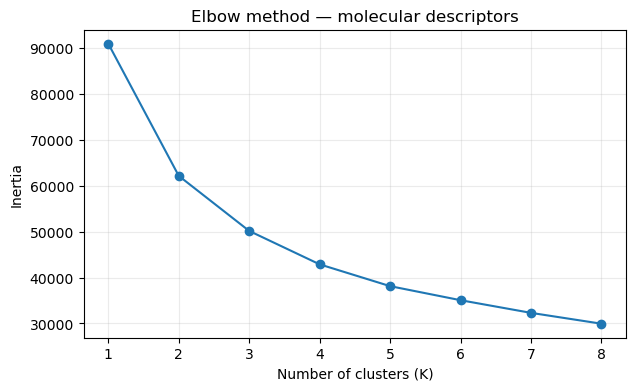

In [4]:
from sklearn.cluster import KMeans

k_values = range(1, 9)
inertias = []

for k in k_values:
    candidate = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    candidate.fit(X_scaled)
    inertias.append(candidate.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow method — molecular descriptors")
plt.grid(alpha=0.25)
plt.show()

## 5. Compare silhouette scores

The silhouette score ranges from -1 to 1. Higher values generally indicate that observations are closer to their own cluster than to other clusters. Use it as a guide alongside the elbow plot and whether the resulting groups are interpretable.

For a large dataset, the score is calculated on a reproducible sample to keep the computation manageable.

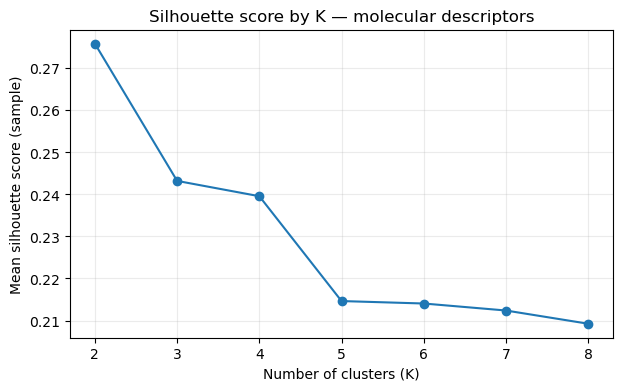

,K,Mean silhouette score
0,2,0.276
1,3,0.243
2,4,0.240
3,5,0.215
4,6,0.214
5,7,0.212
6,8,0.209


In [5]:
from sklearn.metrics import silhouette_score

silhouette_k_values = range(2, 9)
silhouette_scores = []

for k in silhouette_k_values:
    candidate = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    labels = candidate.fit_predict(X_scaled)
    score = silhouette_score(
        X_scaled, labels,
        sample_size=min(5000, len(X_scaled)),
        random_state=42
    )
    silhouette_scores.append(score)

plt.figure(figsize=(7, 4))
plt.plot(list(silhouette_k_values), silhouette_scores, marker="o")
plt.xticks(list(silhouette_k_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Mean silhouette score (sample)")
plt.title("Silhouette score by K — molecular descriptors")
plt.grid(alpha=0.25)
plt.show()

display(pd.DataFrame({
    "K": list(silhouette_k_values),
    "Mean silhouette score": silhouette_scores
}).round(3))

## 6. Fit K-Means

Start with K=3 so that the groups can be inspected and compared. This is an exploratory choice, not a claim that exactly three natural molecule groups exist. If the elbow and silhouette results suggest another value, change `chosen_k` and rerun this section.

In [6]:
chosen_k = 3

kmeans = KMeans(
    n_clusters=chosen_k,
    init="k-means++",
    n_init=20,
    random_state=42
)

cluster_labels = kmeans.fit_predict(X_scaled)

clustered_data = df.copy()
clustered_data["cluster"] = cluster_labels

print("Inertia:", round(kmeans.inertia_, 2))
print("Number of compounds in each cluster:")
display(clustered_data["cluster"].value_counts().sort_index().to_frame("Count"))

Inertia: 50162.55
Number of compounds in each cluster:


,Count
cluster,
0,3340
1,8892
2,2934


## 7. Visualise the clusters

The original teaching notebook used two features for a 2D scatter plot. Here we have six input features, so use PCA to project the standardised data into two dimensions for visualisation.

PCA is used only to make a plot; K-Means was fitted using all six standardised descriptors. The two-dimensional picture therefore does not show every detail of the clustering.

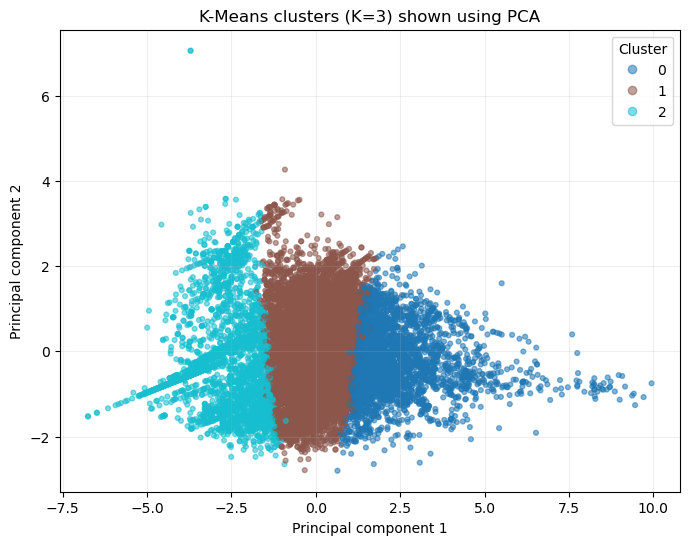

Variance represented by first two principal components: 0.742


In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=cluster_labels, cmap="tab10", alpha=0.55, s=12
)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title(f"K-Means clusters (K={chosen_k}) shown using PCA")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(alpha=0.2)
plt.show()

print("Variance represented by first two principal components:",
      round(pca.explained_variance_ratio_.sum(), 3))

## 8. Describe the clusters

Now examine the original descriptor values and Mannhold LogP within each cluster. LogP is used here for interpretation only; it was not used to assign cluster membership.

The table reports cluster size and median/mean values. Medians are useful because several molecular descriptors have extreme values.

In [8]:
numeric_for_summary = feature_names + ["Mannhold LogP"]
summary_data = clustered_data[numeric_for_summary].apply(
    pd.to_numeric, errors="coerce"
)
summary_data["cluster"] = cluster_labels

cluster_summary = summary_data.groupby("cluster").agg(
    count=("Mannhold LogP", "size"),
    median_logp=("Mannhold LogP", "median"),
    mean_logp=("Mannhold LogP", "mean"),
    median_molecular_weight=("Molecular Weight", "median"),
    median_tpsa=("Topological Polar Surface Area", "median"),
    median_hba=("Hydrogen Bond Acceptors", "median"),
    median_hbd=("Hydrogen Bond Donors", "median"),
    median_rotatable_bonds=("Rotatable Bonds Count", "median"),
    median_sp3=("SP3 Character", "median")
).round(3)

display(cluster_summary)

,count,median_logp,mean_logp,median_molecular_weight,median_tpsa,median_hba,median_hbd,median_rotatable_bonds,median_sp3
cluster,,,,,,,,,
0,3340,2.78,2.899,464.186,143.96,7.0,4.0,13.0,0.174
1,8892,2.56,2.579,284.127,53.09,3.0,1.0,6.0,0.161
2,2934,1.57,1.753,134.950,3.24,0.0,0.0,1.0,0.000


## 9. Compare LogP distributions across clusters

This boxplot can help show whether the clusters formed from molecular descriptors also differ in their LogP distributions. Any difference is descriptive, not proof that cluster membership causes LogP to change.

<Figure size 800x500 with 0 Axes>

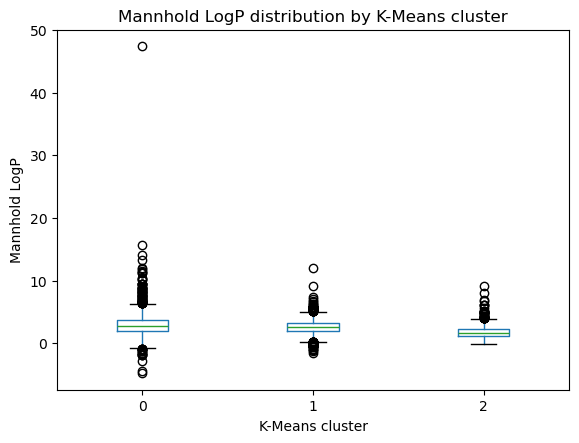

In [9]:
plt.figure(figsize=(8, 5))
clustered_for_plot = clustered_data[["cluster", "Mannhold LogP"]].copy()
clustered_for_plot["Mannhold LogP"] = pd.to_numeric(
    clustered_for_plot["Mannhold LogP"], errors="coerce"
)
clustered_for_plot.boxplot(column="Mannhold LogP", by="cluster", grid=False)
plt.title("Mannhold LogP distribution by K-Means cluster")
plt.suptitle("")
plt.xlabel("K-Means cluster")
plt.ylabel("Mannhold LogP")
plt.show()

## 10. Interpretation and limitations

Use your outputs to answer:

1. What value of K appears reasonable from the elbow plot?
2. Which K has the highest sampled silhouette score?
3. How many compounds are in each cluster?
4. Which clusters have higher or lower median molecular weight, TPSA or LogP?
5. Do the clusters appear meaningfully different, or do they overlap?

### Limitations

- K-Means requires K to be selected in advance.
- Results depend on the features selected, transformations and scaling.
- K-Means favours roughly compact, similarly sized groups and may struggle with irregular shapes.
- Extreme values can affect centroids and distances.
- PCA is only a two-dimensional projection; it can hide separation or overlap present in six dimensions.
- Cluster numbers are arbitrary labels, not rankings.
- Clusters do not automatically represent biological categories or drug activity.
- The dataset has no measured bioactivity labels, so this analysis cannot identify active or inactive compounds.

**Project connection:** K-Means offers an exploratory way to investigate whether compounds form groups with different molecular-property profiles. It complements supervised LogP prediction but does not itself predict LogP or bioactivity.